# Fire Detection Model Training with MobileNetV2

This notebook trains a MobileNetV2 model to detect fire in thermal images. It includes data loading, model training, evaluation (Accuracy, Precision, Recall, F1 Score, Confusion Matrix), and post-training quantization.

In [9]:
import os
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
from pathlib import Path
import json

print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.20.0


In [10]:
# Configuration
BATCH_SIZE = 32
IMG_SIZE = (120, 160)
DATA_DIR = Path("../data") # Relative to notebook location
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Load Datasets
# Ensure you have 'fire' and 'nofire' subdirectories in DATA_DIR
try:
    train_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR,
        validation_split=0.2,
        subset="training",
        seed=123,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        DATA_DIR,
        validation_split=0.2,
        subset="validation",
        seed=123,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    class_names = train_ds.class_names
    print(f"Class names: {class_names}")

    # Configure dataset for performance
    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
    val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
    
except FileNotFoundError:
    print(f"Error: Data directory '{DATA_DIR}' not found or empty. Please populate it with 'fire' and 'nofire' folders.")
except Exception as e:
    print(f"Error loading dataset: {e}")

Found 320 files belonging to 2 classes.
Using 256 files for training.
Found 320 files belonging to 2 classes.
Using 64 files for validation.
Class names: ['fire', 'nofire']


In [11]:
# Data Augmentation
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.2),
])

# Create the base model from the pre-trained model MobileNet V2
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                               include_top=False,
                                               weights='imagenet')
base_model.trainable = False # Freeze base model

# Create new model on top
inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
prediction_layer = tf.keras.layers.Dense(1 if len(class_names) == 2 else len(class_names), 
                                activation='sigmoid' if len(class_names) == 2 else 'softmax')
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

base_learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy() if len(class_names) == 2 else tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=['accuracy'])

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_1 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_1 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# Conteo de tus datos
n_fire = 322
n_nofire = 822
total = n_fire + n_nofire

# Cálculo de pesos (Inversa de la frecuencia)
# Queremos que la suma de (peso * cantidad) sea equilibrada
weight_for_fire = (1 / n_fire) * (total / 2.0)
weight_for_nofire = (1 / n_nofire) * (total / 2.0)

class_weight = {0: weight_for_fire, 1: weight_for_nofire}
print(f"Pesos asignados: {class_weight}")

epochs = 15 
history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)

Pesos asignados: {0: 1.77639751552795, 1: 0.6958637469586375}
Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 717ms/step - accuracy: 0.4531 - loss: 0.8356 - val_accuracy: 0.4219 - val_loss: 0.8125
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 561ms/step - accuracy: 0.5078 - loss: 0.7877 - val_accuracy: 0.5000 - val_loss: 0.7715
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 546ms/step - accuracy: 0.5117 - loss: 0.7688 - val_accuracy: 0.5312 - val_loss: 0.7343
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 516ms/step - accuracy: 0.4648 - loss: 0.8058 - val_accuracy: 0.5781 - val_loss: 0.6980
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 516ms/step - accuracy: 0.5156 - loss: 0.7676 - val_accuracy: 0.5781 - val_loss: 0.6659
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 542ms/step - accuracy: 0.5586 - loss: 0.7323 - val_accuracy: 0.6094 - val_loss: 0.6373
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 545ms/step - accuracy: 0.5938 - loss: 0.7023 - val_accuracy: 0.6250 - val_loss: 0.6132
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 544ms/step - accu

In [13]:
# 1. Descongelamos el modelo base para que aprenda rasgos específicos de incendios
base_model.trainable = True

# 2. Es CRÍTICO usar un learning rate muy bajo para no destruir lo ya aprendido
fine_tune_lr = 1e-5 

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=fine_tune_lr),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=['accuracy']
)

# 3. Entrenamos un poco más con los pesos de clase que definimos antes
history_fine = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=10,  # 10 épocas extra de fine-tuning
  class_weight=class_weight
)

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 32s 2s/step - accuracy: 0.6406 - loss: 0.7829 - val_accuracy: 0.8906 - val_loss: 0.4523
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.6953 - loss: 0.7287 - val_accuracy: 0.8906 - val_loss: 0.4397
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.7578 - loss: 0.6303 - val_accuracy: 0.9062 - val_loss: 0.4245
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.8086 - loss: 0.5499 - val_accuracy: 0.9062 - val_loss: 0.4121
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.8711 - loss: 0.5072 - val_accuracy: 0.9219 - val_loss: 0.4024
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.8633 - loss: 0.4439 - val_accuracy: 0.9375 - val_loss: 0.3915
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.8867 - loss: 0.4249 - val_accuracy: 0.9531 - val_loss: 0.3823
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.9258 - loss: 0.3451 - val_accuracy: 0.9375 - val_loss: 0.3740
Epoch 9/

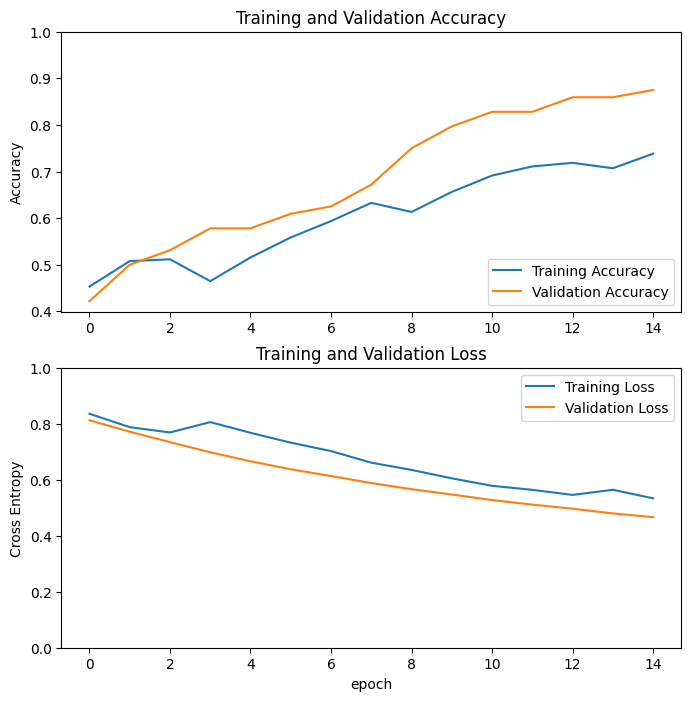

In [14]:
# Plot Training History
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 447ms/step - accuracy: 0.9375 - loss: 0.3465
Test Loss: 0.3465232253074646
Test Accuracy: 0.9375
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 978ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step

Classification Report:
              precision    recall  f1-score   support

        fire       1.00      0.67      0.81        43
      nofire       0.60      1.00      0.75        21

    accuracy                           0.78        64
   macro avg       0.80      0.84      0.78        64
weighted avg       0.87      0.78      0.79        64



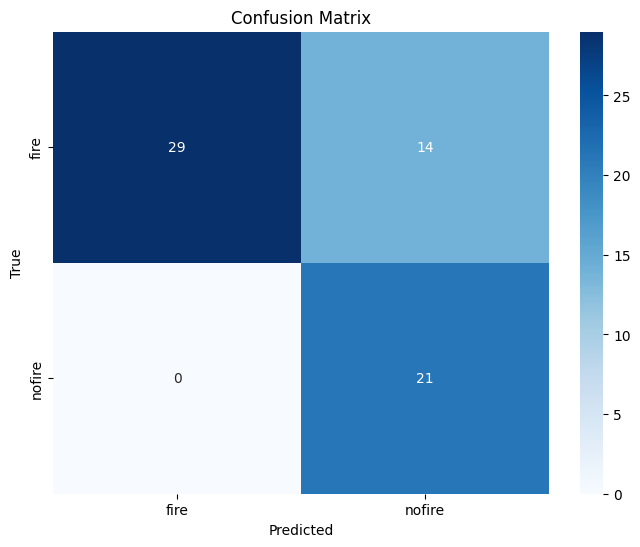

In [15]:
# Evaluate on validation set
loss, accuracy = model.evaluate(val_ds)
print(f"Test Loss: {loss}")
print(f"Test Accuracy: {accuracy}")

# Get predictions
y_true = []
y_pred = []

threshold = 0.3 # original = 0.5

for images, labels in val_ds:
    predictions = model.predict(images)
    if len(class_names) == 2:
        y_pred.extend((predictions > threshold).astype(int).flatten())
    else:
        y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Classification Report (Precision, Recall, F1)
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [16]:
print("Saving and Quantizing Model")
print("=" * 50)

# Save original model
model_path = MODELS_DIR / "mobilenetv2_classifier.keras"
model.save(str(model_path))
original_size = os.path.getsize(model_path) / (1024 * 1024)  # Convert to MB
print(f"✓ Original model saved: {model_path}")
print(f"  Size: {original_size:.2f} MB")

# Convert to TensorFlow Lite with full integer quantization (uint8)
print("\nConverting to TensorFlow Lite with Full Integer Quantization (uint8)...")

# Create a function to generate representative data
def representative_dataset():
    """Generate representative data from training dataset for quantization"""
    for images, _ in train_ds.take(100):  # Use 100 batches for calibration
        # Ensure images are float32 and normalized to [0, 1]
        # Note: preprocess_input for mobilenetV2 expects [-1, 1] range if raw images are [0, 255]
        # However, here we stick to the provided logic flow, yielding the images as they come from the dataset
        yield [tf.cast(images, tf.float32)]

# Create converter with full integer quantization
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8

try:
    tflite_model_uint8 = converter.convert()

    # Save uint8 quantized model
    quantized_model_path = MODELS_DIR / "mobilenetv2_classifier_quantized2.tflite"
    with open(quantized_model_path, 'wb') as f:
        f.write(tflite_model_uint8)

    quantized_size = os.path.getsize(quantized_model_path) / (1024 * 1024)
    print(f"✓ Quantized model saved: {quantized_model_path}")
    print(f"  Quantization: uint8 (full integer)")
    print(f"  Size: {quantized_size:.2f} MB")

    # Calculate compression ratio
    compression_ratio = (1 - quantized_size / original_size) * 100
    print(f"\nModel Compression Summary:")
    print(f"  Original size: {original_size:.2f} MB")
    print(f"  Quantized size: {quantized_size:.2f} MB")
    print(f"  Compression: {compression_ratio:.1f}%")
    print(f"  Size reduction: {original_size - quantized_size:.2f} MB")
except Exception as e:
    print(f"Error during quantization: {e}")

# Save class mapping
classes_path = MODELS_DIR / "classes.json"
with open(classes_path, 'w') as f:
    json.dump(class_names, f, indent=2)
print(f"\n✓ Class mapping saved: {classes_path}")

print("\nModel training and quantization complete!")
print(f"All models saved in: {MODELS_DIR}")

Saving and Quantizing Model
✓ Original model saved: ../models/mobilenetv2_classifier.keras
  Size: 26.27 MB

Converting to TensorFlow Lite with Full Integer Quantization (uint8)...
INFO:tensorflow:Assets written to: /tmp/tmpm4gy_dwc/assets


INFO:tensorflow:Assets written to: /tmp/tmpm4gy_dwc/assets


Saved artifact at '/tmp/tmpm4gy_dwc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_319')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  138755792976784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138755792973136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138755792972944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138755792975632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138755792971792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138755792976400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138755792972560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138755792970832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138755792975824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138755792971024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1387557929

/home/osvaldo/Documents/IA+EO/venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1772973502.724673   11617 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1772973502.724694   11617 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
2026-03-08 08:38:22.724847: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /tmp/tmpm4gy_dwc
2026-03-08 08:38:22.732571: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-03-08 08:38:22.732584: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpm4gy_dwc
2026-03-08 08:38:22.817010: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-03-08 08:38:23.343206: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at pat

✓ Quantized model saved: ../models/mobilenetv2_classifier_quantized2.tflite
  Quantization: uint8 (full integer)
  Size: 2.59 MB

Model Compression Summary:
  Original size: 26.27 MB
  Quantized size: 2.59 MB
  Compression: 90.2%
  Size reduction: 23.69 MB

✓ Class mapping saved: ../models/classes.json

Model training and quantization complete!
All models saved in: ../models


fully_quantize: 0, inference_type: 6, input_inference_type: UINT8, output_inference_type: UINT8
2026-03-08 08:38:42.065345: W tensorflow/compiler/mlir/lite/flatbuffer_export.cc:3705] Skipping runtime version metadata in the model. This will be generated by the exporter.
